In [4]:
import pandas as pd

# Orijinal UCI Machine Learning Repository resmi veri seti bağlantısı
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv"
df = pd.read_csv(url)

print("Veri Seti Başarıyla Çekildi! Boyut:", df.shape)
display(df.head())

Veri Seti Başarıyla Çekildi! Boyut: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


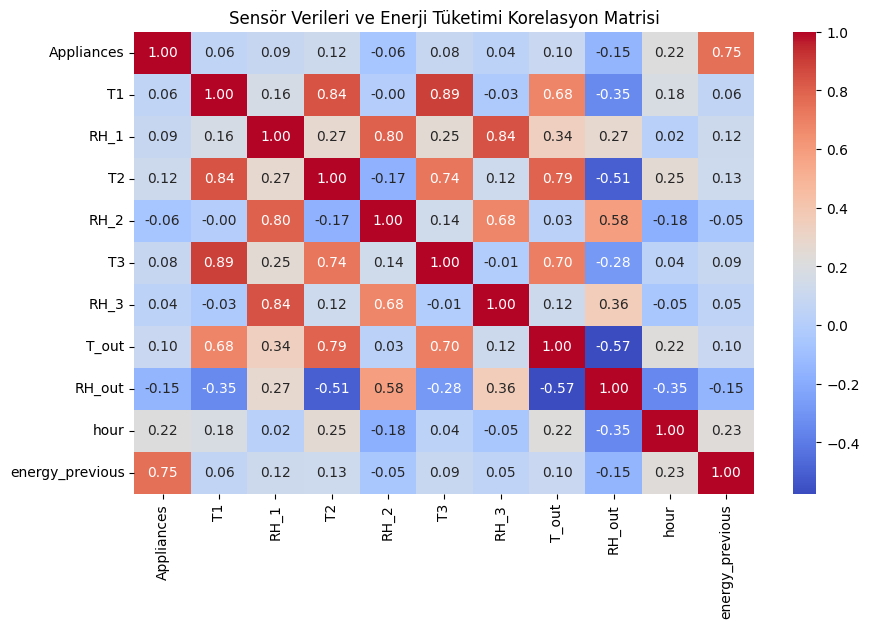

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tarih sütununu zaman formatına çevir ve takvim değişkenleri üret
df['date'] = pd.to_datetime(df['date'])
df['hour'] = df['date'].dt.hour
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.weekday

# Geçmiş tüketim (Lag) değişkenlerini oluştur
df['energy_previous'] = df['Appliances'].shift(1)
df['energy_1_step_ago'] = df['Appliances'].shift(2)
df['energy_2_step_ago'] = df['Appliances'].shift(3)
df.dropna(inplace=True)

# Seçili özelliklerin korelasyon matrisi
features = ['Appliances', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T_out', 'RH_out', 'hour', 'energy_previous']
plt.figure(figsize=(10, 6))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Sensör Verileri ve Enerji Tüketimi Korelasyon Matrisi")
plt.show()

,Model,MAE (Wh),RMSE (Wh),R2 Skoru
0,Linear Regression,29.23,61.49,0.611
1,Decision Tree,29.28,68.77,0.513
2,Random Forest,27.63,59.62,0.634


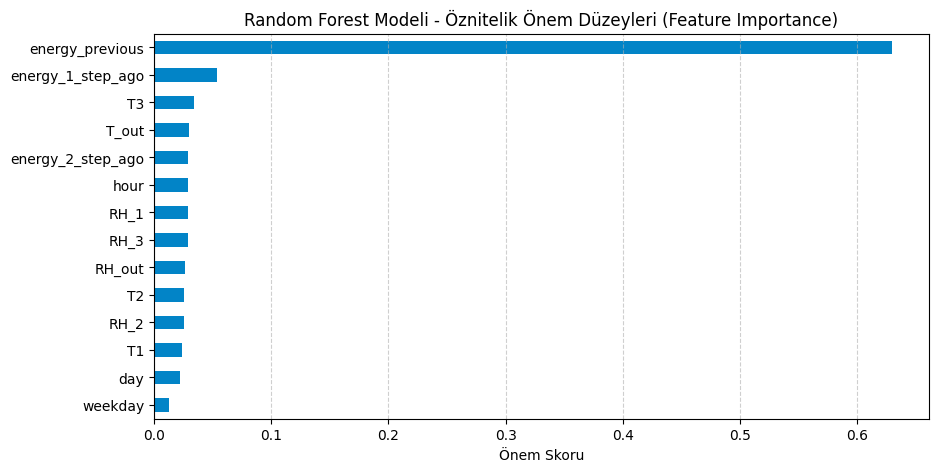

In [10]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Girdi (X) ve Hedef (y) değişkenleri
X = df[['T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T_out', 'RH_out',
        'hour', 'day', 'weekday', 'energy_previous', 'energy_1_step_ago', 'energy_2_step_ago']]
y = df['Appliances']

# Eğitim ve Test olarak böl (%80 Eğitim, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3 Farklı Modeli Kıyasla
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE (Wh)": round(mean_absolute_error(y_test, preds), 2),
        "RMSE (Wh)": round(np.sqrt(mean_squared_error(y_test, preds)), 2),
        "R2 Skoru": round(r2_score(y_test, preds), 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

# Şampiyon Random Forest modelinin karar verirken en çok önem verdiği değişkenler
rf_model = models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
importances.plot(kind='barh', color='#0284c7')
plt.title("Random Forest Modeli - Öznitelik Önem Düzeyleri (Feature Importance)")
plt.xlabel("Önem Skoru")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()